# DUR 임부금기 1등급 판별 — RNN(LSTM) 모형의 노드 수·층 수에 따른 성능 변화

**과제**
1. DUR 데이터의 **[상세정보]** 텍스트를 입력으로 **[임부금기] 1등급 여부**(1등급=1, 그 외=0)를 판별하는 모형을 구성한다.
2. RNN 계열 알고리즘 중 **LSTM**을 선택한다.
3. **노드 수 8 / 32 / 128** (1층 고정), **층 수 1 / 2 / 3** (노드 32 고정)일 때 각각
   **파라미터 수, 학습 시간, 학습 정확도, 검증 정확도, F1 스코어**를 계산한다.
4. 결과를 해석한다.

> 실행 환경: Google Colab (TensorFlow 2.x / Keras). GPU 런타임이면 더 빠르지만 CPU에서도 돌아갑니다.
> `preg.csv` 파일을 노트북과 같은 폴더(Colab이면 `/content/`)에 올려두고 위에서부터 실행하세요.

## 0. 라이브러리 및 실험 설정

In [1]:
import os, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

SEED = 42
def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
set_seed()

# ---- 실험 공통 하이퍼파라미터 (비교를 위해 모든 모형에 동일 적용) ----
from google.colab import drive
drive.mount('/content/drive')
DATA_PATH  = "/content/drive/MyDrive/ai 헬스케어 7기/진료 기록 요약을 위한 자연어 처리(NLP)/07_DUR_Data/의약품안전사용서비스(DUR)_임부금기 품목리스트 2026.6.csv"
MAXLEN     = 256    # 상세정보 최대 글자 수 (95% 분위수 ≈ 270자)
EMB_DIM    = 32     # 문자 임베딩 차원
EPOCHS     = 20
BATCH_SIZE = 32
LR         = 1e-3
THRESHOLD  = 0.5    # 1등급 판정 임계값

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive


## 1. 데이터 불러오기 및 확인
원본 파일은 **CP949** 인코딩입니다.

In [2]:
df_raw = pd.read_csv(DATA_PATH, encoding="cp949")
print(df_raw.shape)
display(df_raw.head())
print(df_raw["금기등급"].value_counts(dropna=False))

(19015, 10)


,성분명,성분코드,제품코드,제품명,업체명,고시일자,고시번호,금기등급,상세정보,급여여부
0,Chenodeoxycholic acid + Ursodeoxycholic acid,100301ACH,649804410.0,씨앤유캡슐(케노데속시콜산-우르소데속시콜산삼수화물마그네슘염)_(0.25g/1캡슐),명문제약(주),2020-12-28,20200130.0,1,"임부 투여금기, 동물실험에서 간독성의 증거 나타남",급여
1,acamprosate,100501ATE,651904740.0,명인아캄프로세이트정333mg(아캄프로세이트칼슘)_(0.333g/1정),명인제약(주),2016-12-30,20160155.0,2,임부에 대한 안전성 미확립.,급여
2,acamprosate,100501ATE,657201040.0,환인아캄프로세이트정(아캄프로세이트칼슘)_(0.333g/1정),환인제약(주),2016-12-30,20160155.0,2,임부에 대한 안전성 미확립.,급여
3,acarbose,100601ATB,652100060.0,글루코바이정100밀리그람(아카보즈)_(0.1g/1정),(주)한독,2016-12-30,20160155.0,2,임부에 대한 안전성 미확립.,급여
4,acarbose,100602ATB,652100050.0,글루코바이정50밀리그람(아카보즈)_(50mg/1정),(주)한독,2016-12-30,20160155.0,2,임부에 대한 안전성 미확립.,급여


금기등급
2      15480
1       3132
NaN      344
M         59
Name: count, dtype: int64


## 2. 전처리

1. `상세정보`, `금기등급`이 비어 있는 행(빈 줄) 제거
2. **타깃**: `금기등급 == '1'` → 1, 그 외(`2`, `M`) → 0
3. **중복 제거 (중요)**
   - 약 1.8만 행이지만 `상세정보` 문장 종류는 약 1,060개뿐입니다. 같은 성분의 여러 제품이 **동일 문장**을 공유하기 때문입니다.
   - 행 단위로 나누면 같은 문장이 학습·검증 양쪽에 들어가 **검증 정확도가 부풀려집니다(데이터 누수)**.
   - 따라서 **고유 문장 단위로 중복 제거**하고, 한 문장에 여러 등급이 붙은 소수의 경우(10건 내외)는 **다수결 라벨**을 씁니다.

In [3]:
df = df_raw.dropna(subset=["상세정보", "금기등급"]).copy()
df["상세정보"] = df["상세정보"].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
df["label"] = (df["금기등급"].astype(str).str.strip() == "1").astype(int)
print("행 단위:", len(df), "| 1등급 비율: %.3f" % df["label"].mean())

# 한 문장에 등급이 둘 이상 붙은 경우 확인
n_conflict = (df.groupby("상세정보")["label"].nunique() > 1).sum()
print("라벨이 엇갈리는 문장 수:", n_conflict)

data = (df.groupby("상세정보")["label"]
          .agg(lambda s: int(s.mean() >= 0.5))
          .reset_index())
print("고유 문장 단위:", len(data))
print(data["label"].value_counts().rename({0: "비1등급(0)", 1: "1등급(1)"}))

data["상세정보"].str.len().describe()

행 단위: 18381 | 1등급 비율: 0.167
라벨이 엇갈리는 문장 수: 10
고유 문장 단위: 1061
label
비1등급(0)    874
1등급(1)     187
Name: count, dtype: int64


,상세정보
count,1061.000000
mean,97.380773
std,80.045200
min,1.000000
25%,40.000000
50%,72.000000
75%,126.000000
max,550.000000


### 학습 / 검증 분할
층화추출(stratify)로 1등급 비율을 유지하며 8:2로 나눕니다.

In [4]:
train_df, val_df = train_test_split(data, test_size=0.2, stratify=data["label"], random_state=SEED)
print("train:", train_df.shape, "positive rate %.3f" % train_df["label"].mean())
print("val  :", val_df.shape,   "positive rate %.3f" % val_df["label"].mean())

train: (848, 2) positive rate 0.176
val  : (213, 2) positive rate 0.178


### 문자(음절) 단위 토큰화
상세정보는 한국어·영어(성분명)가 섞인 짧은 의학 문장이라 형태소 분석기 없이 **문자 단위**로 토큰화합니다.
- 사전은 **학습 데이터로만** 구축 (0 = 패딩, 1 = 미등록 문자 OOV)
- 길이는 `MAXLEN`에 맞춰 **뒤쪽 패딩/자르기**(post) — cuDNN LSTM의 마스킹 조건과도 맞습니다.

In [5]:
PAD, OOV = 0, 1
char_counts = Counter(ch for t in train_df["상세정보"] for ch in t)
char2idx = {ch: i + 2 for i, (ch, _) in enumerate(char_counts.most_common())}
VOCAB_SIZE = len(char2idx) + 2
print("VOCAB_SIZE:", VOCAB_SIZE)

def encode(texts, maxlen=MAXLEN):
    X = np.zeros((len(texts), maxlen), dtype="int32")
    for i, t in enumerate(texts):
        ids = [char2idx.get(ch, OOV) for ch in t][:maxlen]
        X[i, :len(ids)] = ids
    return X

X_train, y_train = encode(train_df["상세정보"].tolist()), train_df["label"].values
X_val,   y_val   = encode(val_df["상세정보"].tolist()),   val_df["label"].values
print(X_train.shape, X_val.shape)
print("예시:", train_df["상세정보"].iloc[0][:40], "→", X_train[0][:20])

VOCAB_SIZE: 585
(848, 256) (213, 256)
예시: 임부에 대한 안전성 미확립.태아에 고칼륨혈증 및 신기능장애 나타남.동물실 → [10 11  3  2 23 17  2 29 15  4  2 42 35 48  6  7  8  3  2 20]


### 클래스 불균형 처리
1등급은 약 18%뿐이라, 그대로 학습하면 전부 0으로 찍어도 정확도 82%가 나옵니다.
손실 함수에 **class_weight(balanced)** 를 줘서 소수 클래스(1등급)를 놓치는 데 더 큰 벌점을 줍니다.
이 때문에 정확도만이 아니라 **F1(1등급 기준)** 을 함께 봐야 합니다.

In [6]:
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
CLASS_WEIGHT = {0: cw[0], 1: cw[1]}
CLASS_WEIGHT

{0: np.float64(0.6065808297567954), 1: np.float64(2.8456375838926173)}

## 3. 모형 구성 — LSTM

```
Input(글자 인덱스, 길이 256)
 → Embedding(VOCAB_SIZE, 32, mask_zero=True)
 → LSTM(units) × n_layers   (마지막 층을 제외하면 return_sequences=True)
 → Dense(1, sigmoid)        → 1등급 확률
```

**LSTM을 고른 이유**: 상세정보는 평균 90자, 길게는 500자 이상인 문장입니다. 단순 RNN은 긴 시퀀스에서 기울기 소실로 앞부분 정보(예: "임부 투여금기", "기형 유발")를 잊기 쉬운데, LSTM은 게이트(입력·망각·출력)와 셀 상태로 장기 의존성을 유지합니다.

모든 모형은 **같은 시드, 같은 에폭(20), 같은 배치(32), 같은 학습률**로 학습해 노드·층 수의 효과만 비교합니다.

In [7]:
def build_model(units=32, n_layers=1):
    set_seed()
    model = keras.Sequential(name=f"LSTM_u{units}_L{n_layers}")
    model.add(keras.Input(shape=(MAXLEN,), dtype="int32"))
    model.add(layers.Embedding(VOCAB_SIZE, EMB_DIM, mask_zero=True, name="embedding"))
    for i in range(n_layers):
        model.add(layers.LSTM(units, return_sequences=(i < n_layers - 1), name=f"lstm_{i+1}"))
    model.add(layers.Dense(1, activation="sigmoid", name="output"))
    model.compile(optimizer=keras.optimizers.Adam(LR),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

build_model(32, 1).summary()

Model: "LSTM_u32_L1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 256, 32)        │        18,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,073 (105.75 KB)

 Trainable params: 27,073 (105.75 KB)

 Non-trainable params: 0 (0.00 B)

### 파라미터 수 공식 (검증용)

LSTM 한 층의 파라미터 수 = **4 × [ units × (입력차원 + units) + units ]**
(4 = 입력·망각·출력 게이트 + 후보 셀, 각 게이트마다 입력가중치 + 순환가중치 + 편향)

- 임베딩: `VOCAB_SIZE × 32`
- LSTM 1층: 입력차원 = 32(임베딩) → `4 × (u(32+u) + u)`
- LSTM 2층 이상: 입력차원 = u → `4 × (u·2u + u)`
- 출력층: `u + 1`

In [8]:
def lstm_params(inp, u): return 4 * (u * (inp + u) + u)

def formula_params(units, n_layers):
    emb = VOCAB_SIZE * EMB_DIM
    rnn = lstm_params(EMB_DIM, units) + (n_layers - 1) * lstm_params(units, units)
    out = units + 1
    return emb, rnn, out, emb + rnn + out

for u, L in [(8,1),(32,1),(128,1),(32,2),(32,3)]:
    emb, rnn, out, tot = formula_params(u, L)
    print(f"units={u:>3}, layers={L}: 임베딩 {emb:,} + LSTM {rnn:,} + 출력 {out} = 총 {tot:,}"
          f"  | Keras count_params = {build_model(u, L).count_params():,}")

units=  8, layers=1: 임베딩 18,720 + LSTM 1,312 + 출력 9 = 총 20,041  | Keras count_params = 20,041
units= 32, layers=1: 임베딩 18,720 + LSTM 8,320 + 출력 33 = 총 27,073  | Keras count_params = 27,073
units=128, layers=1: 임베딩 18,720 + LSTM 82,432 + 출력 129 = 총 101,281  | Keras count_params = 101,281
units= 32, layers=2: 임베딩 18,720 + LSTM 16,640 + 출력 33 = 총 35,393  | Keras count_params = 35,393
units= 32, layers=3: 임베딩 18,720 + LSTM 24,960 + 출력 33 = 총 43,713  | Keras count_params = 43,713


## 4. 실험 함수

In [9]:
class TimeHistory(keras.callbacks.Callback):
    # 에폭별 소요 시간 기록
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self._t = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.perf_counter() - self._t)

def run_experiment(units, n_layers, verbose=0):
    keras.backend.clear_session()
    model = build_model(units, n_layers)
    timer = TimeHistory()

    t0 = time.perf_counter()
    hist = model.fit(X_train, y_train,
                     validation_data=(X_val, y_val),
                     epochs=EPOCHS, batch_size=BATCH_SIZE,
                     class_weight=CLASS_WEIGHT,
                     callbacks=[timer], verbose=verbose)
    train_time = time.perf_counter() - t0

    # 학습이 끝난 최종 모형으로 평가
    p_tr  = model.predict(X_train, verbose=0).ravel()
    p_val = model.predict(X_val,   verbose=0).ravel()
    yhat_tr, yhat_val = (p_tr >= THRESHOLD).astype(int), (p_val >= THRESHOLD).astype(int)

    emb, rnn, out, _ = formula_params(units, n_layers)
    result = {
        "units": units, "layers": n_layers,
        "총 파라미터 수": model.count_params(),
        "LSTM 파라미터 수": rnn,
        "학습 시간(초)": round(train_time, 1),
        "에폭당 시간(초)": round(float(np.mean(timer.times[1:])), 2),  # 첫 에폭(그래프 컴파일) 제외
        "학습 정확도": accuracy_score(y_train, yhat_tr),
        "검증 정확도": accuracy_score(y_val, yhat_val),
        "학습 F1": f1_score(y_train, yhat_tr),
        "검증 F1": f1_score(y_val, yhat_val),
    }
    print(f"[{model.name}] params={result['총 파라미터 수']:,}  time={result['학습 시간(초)']}s  "
          f"train_acc={result['학습 정확도']:.4f}  val_acc={result['검증 정확도']:.4f}  val_F1={result['검증 F1']:.4f}")
    return result, hist.history, (y_val, yhat_val)

## 5. 실험 ① 노드 수 변화 — 8 / 32 / 128 (1층 고정)

In [10]:
node_results, node_hist, node_pred = [], {}, {}
for u in [8, 32, 128]:
    r, h, p = run_experiment(units=u, n_layers=1)
    node_results.append(r); node_hist[u] = h; node_pred[u] = p

node_df = pd.DataFrame(node_results).set_index("units")
node_df.style.format({"총 파라미터 수": "{:,}", "LSTM 파라미터 수": "{:,}",
                      "학습 정확도": "{:.4f}", "검증 정확도": "{:.4f}",
                      "학습 F1": "{:.4f}", "검증 F1": "{:.4f}"})

[LSTM_u8_L1] params=20,041  time=12.8s  train_acc=0.8809  val_acc=0.7840  val_F1=0.5000
[LSTM_u32_L1] params=27,073  time=10.7s  train_acc=0.7795  val_acc=0.7089  val_F1=0.4833
[LSTM_u128_L1] params=101,281  time=10.2s  train_acc=0.8868  val_acc=0.8028  val_F1=0.4167


,layers,총 파라미터 수,LSTM 파라미터 수,학습 시간(초),에폭당 시간(초),학습 정확도,검증 정확도,학습 F1,검증 F1
units,,,,,,,,,
8,1,"20,041","1,312",12.800000,0.410000,0.8809,0.7840,0.7430,0.5000
32,1,"27,073","8,320",10.700000,0.470000,0.7795,0.7089,0.6112,0.4833
128,1,"101,281","82,432",10.200000,0.430000,0.8868,0.8028,0.6779,0.4167


## 6. 실험 ② 층 수 변화 — 1 / 2 / 3층 (노드 32 고정)

In [11]:
layer_results, layer_hist, layer_pred = [], {}, {}
for L in [1, 2, 3]:
    r, h, p = run_experiment(units=32, n_layers=L)
    layer_results.append(r); layer_hist[L] = h; layer_pred[L] = p

layer_df = pd.DataFrame(layer_results).set_index("layers")
layer_df.style.format({"총 파라미터 수": "{:,}", "LSTM 파라미터 수": "{:,}",
                       "학습 정확도": "{:.4f}", "검증 정확도": "{:.4f}",
                       "학습 F1": "{:.4f}", "검증 F1": "{:.4f}"})

[LSTM_u32_L1] params=27,073  time=9.8s  train_acc=0.8998  val_acc=0.7793  val_F1=0.5347
[LSTM_u32_L2] params=35,393  time=15.8s  train_acc=0.9528  val_acc=0.8685  val_F1=0.5758
[LSTM_u32_L3] params=43,713  time=20.6s  train_acc=0.8715  val_acc=0.7653  val_F1=0.5283


,units,총 파라미터 수,LSTM 파라미터 수,학습 시간(초),에폭당 시간(초),학습 정확도,검증 정확도,학습 F1,검증 F1
layers,,,,,,,,,
1,32,"27,073","8,320",9.800000,0.420000,0.8998,0.7793,0.7733,0.5347
2,32,"35,393","16,640",15.800000,0.650000,0.9528,0.8685,0.8693,0.5758
3,32,"43,713","24,960",20.600000,0.900000,0.8715,0.7653,0.7282,0.5283


## 7. 결과 정리 및 시각화

In [12]:
summary = pd.concat([
    node_df.reset_index().assign(실험="① 노드 수", 설정=lambda d: "units=" + d["units"].astype(str) + ", 1층"),
    layer_df.reset_index().assign(실험="② 층 수",  설정=lambda d: "units=32, " + d["layers"].astype(str) + "층"),
])[["실험", "설정", "총 파라미터 수", "LSTM 파라미터 수", "학습 시간(초)", "에폭당 시간(초)",
   "학습 정확도", "검증 정확도", "학습 F1", "검증 F1"]].reset_index(drop=True)
summary["과적합 갭(학습-검증 정확도)"] = summary["학습 정확도"] - summary["검증 정확도"]
summary.to_csv("dur_lstm_results.csv", index=False, encoding="utf-8-sig")
summary.round(4)

,실험,설정,총 파라미터 수,LSTM 파라미터 수,학습 시간(초),에폭당 시간(초),학습 정확도,검증 정확도,학습 F1,검증 F1,과적합 갭(학습-검증 정확도)
0,① 노드 수,"units=8, 1층",20041,1312,12.8,0.41,0.8809,0.7840,0.7430,0.5000,0.0969
1,① 노드 수,"units=32, 1층",27073,8320,10.7,0.47,0.7795,0.7089,0.6112,0.4833,0.0706
2,① 노드 수,"units=128, 1층",101281,82432,10.2,0.43,0.8868,0.8028,0.6779,0.4167,0.0840
3,② 층 수,"units=32, 1층",27073,8320,9.8,0.42,0.8998,0.7793,0.7733,0.5347,0.1204
4,② 층 수,"units=32, 2층",35393,16640,15.8,0.65,0.9528,0.8685,0.8693,0.5758,0.0843
5,② 층 수,"units=32, 3층",43713,24960,20.6,0.90,0.8715,0.7653,0.7282,0.5283,0.1062


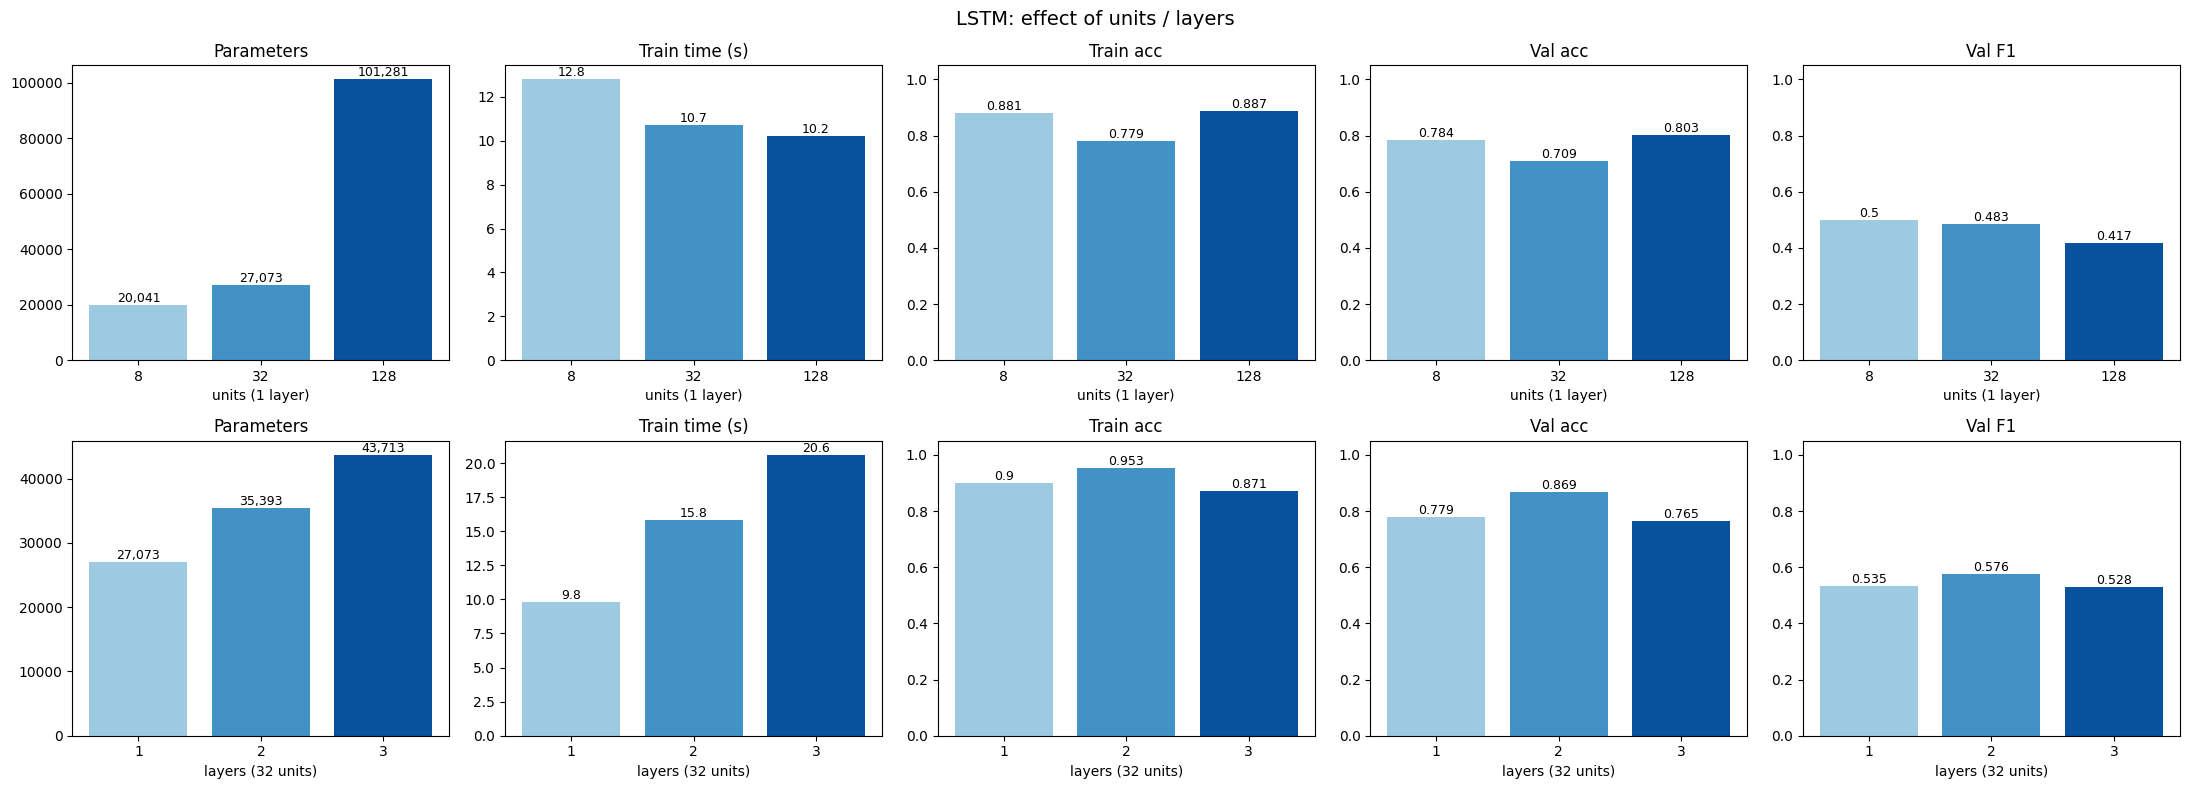

In [13]:
# 그래프 라벨은 한글 폰트 문제를 피하려고 영어로 표기
metrics = [("총 파라미터 수", "Parameters"), ("학습 시간(초)", "Train time (s)"),
           ("학습 정확도", "Train acc"), ("검증 정확도", "Val acc"), ("검증 F1", "Val F1")]

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for row, (frame, xlab, xs) in enumerate([(node_df, "units (1 layer)", ["8", "32", "128"]),
                                         (layer_df, "layers (32 units)", ["1", "2", "3"])]):
    for col, (m, name) in enumerate(metrics):
        ax = axes[row, col]
        vals = frame[m].values
        ax.bar(xs, vals, color=["#9ecae1", "#4292c6", "#08519c"])
        for i, v in enumerate(vals):
            ax.text(i, v, f"{v:,.0f}" if m in ("총 파라미터 수",) else f"{v:.3g}", ha="center", va="bottom", fontsize=9)
        ax.set_title(name); ax.set_xlabel(xlab)
        if "acc" in name or "F1" in name: ax.set_ylim(0, 1.05)
plt.suptitle("LSTM: effect of units / layers", fontsize=14)
plt.tight_layout(); plt.show()

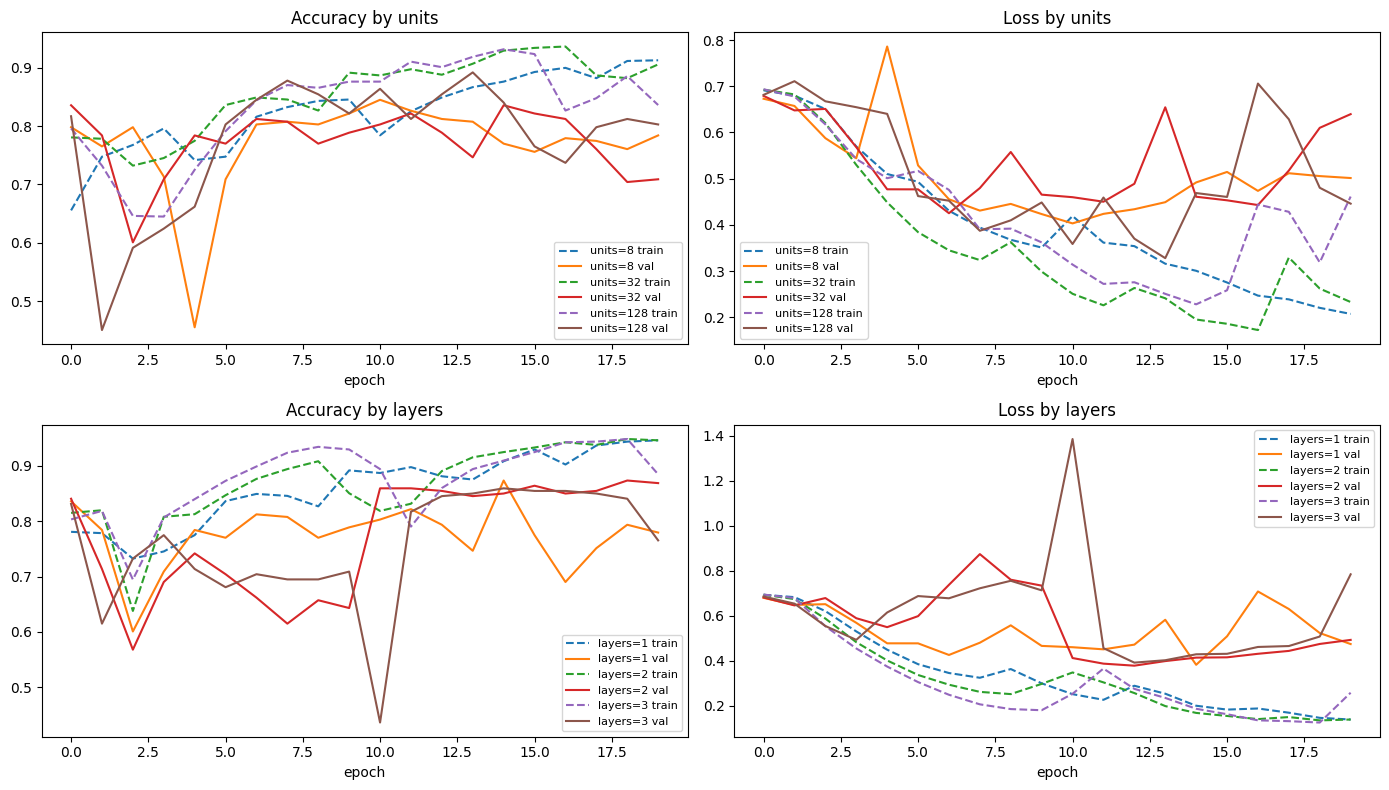

In [14]:
# 학습 곡선 (검증 손실이 다시 오르면 과적합 신호)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, (hdict, lab) in enumerate([(node_hist, "units"), (layer_hist, "layers")]):
    for k, h in hdict.items():
        axes[row, 0].plot(h["accuracy"], "--", label=f"{lab}={k} train")
        axes[row, 0].plot(h["val_accuracy"], label=f"{lab}={k} val")
        axes[row, 1].plot(h["loss"], "--", label=f"{lab}={k} train")
        axes[row, 1].plot(h["val_loss"], label=f"{lab}={k} val")
    axes[row, 0].set_title(f"Accuracy by {lab}"); axes[row, 1].set_title(f"Loss by {lab}")
    for ax in axes[row]: ax.set_xlabel("epoch"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [15]:
# 검증 F1이 가장 높은 설정의 상세 평가
best = summary.loc[summary["검증 F1"].idxmax()]
print("최고 검증 F1 설정:", best["실험"], best["설정"], f"(F1={best['검증 F1']:.4f})")
key = best["설정"]
yv, yh = (node_pred[int(key.split(",")[0].split("=")[1])] if best["실험"].startswith("①")
          else layer_pred[int(key.split(", ")[1][0])])
print(confusion_matrix(yv, yh))
print(classification_report(yv, yh, target_names=["비1등급", "1등급"], digits=4))

최고 검증 F1 설정: ② 층 수 units=32, 2층 (F1=0.5758)
[[166   9]
 [ 19  19]]
              precision    recall  f1-score   support

        비1등급     0.8973    0.9486    0.9222       175
         1등급     0.6786    0.5000    0.5758        38

    accuracy                         0.8685       213
   macro avg     0.7879    0.7243    0.7490       213
weighted avg     0.8583    0.8685    0.8604       213



## 8. 결과 해석 보조 (자동 요약)
아래 셀은 위 표의 실제 수치를 읽어 핵심 비교를 문장으로 뽑아줍니다. 9장 해석과 함께 보세요.

In [16]:
def describe(frame, key_name):
    k = frame.index.tolist()
    lines = []
    p0, p1 = frame["총 파라미터 수"].iloc[0], frame["총 파라미터 수"].iloc[-1]
    r0, r1 = frame["LSTM 파라미터 수"].iloc[0], frame["LSTM 파라미터 수"].iloc[-1]
    t0, t1 = frame["학습 시간(초)"].iloc[0], frame["학습 시간(초)"].iloc[-1]
    lines.append(f"- {key_name} {k[0]}→{k[-1]}: LSTM 파라미터 {r0:,}→{r1:,} ({r1/r0:.1f}배), 총 파라미터 {p0:,}→{p1:,} ({p1/p0:.1f}배)")
    lines.append(f"- 학습 시간 {t0:.1f}s → {t1:.1f}s ({t1/t0:.1f}배)")
    bf = frame["검증 F1"].idxmax(); ba = frame["검증 정확도"].idxmax()
    lines.append(f"- 검증 F1 최고: {key_name}={bf} ({frame.loc[bf,'검증 F1']:.4f}), 검증 정확도 최고: {key_name}={ba} ({frame.loc[ba,'검증 정확도']:.4f})")
    gap = frame["학습 정확도"] - frame["검증 정확도"]
    lines.append("- 과적합 갭(학습-검증 정확도): " + ", ".join(f"{key_name}={i}: {g:+.4f}" for i, g in gap.items()))
    return "\n".join(lines)

print("[실험 ① 노드 수]\n" + describe(node_df, "units"))
print("\n[실험 ② 층 수]\n" + describe(layer_df, "layers"))

[실험 ① 노드 수]
- units 8→128: LSTM 파라미터 1,312→82,432 (62.8배), 총 파라미터 20,041→101,281 (5.1배)
- 학습 시간 12.8s → 10.2s (0.8배)
- 검증 F1 최고: units=8 (0.5000), 검증 정확도 최고: units=128 (0.8028)
- 과적합 갭(학습-검증 정확도): units=8: +0.0969, units=32: +0.0706, units=128: +0.0840

[실험 ② 층 수]
- layers 1→3: LSTM 파라미터 8,320→24,960 (3.0배), 총 파라미터 27,073→43,713 (1.6배)
- 학습 시간 9.8s → 20.6s (2.1배)
- 검증 F1 최고: layers=2 (0.5758), 검증 정확도 최고: layers=2 (0.8685)
- 과적합 갭(학습-검증 정확도): layers=1: +0.1204, layers=2: +0.0843, layers=3: +0.1062


## 9. 모형 평가 결과 해석

### (1) 파라미터 수 — 노드 수는 **제곱**, 층 수는 **선형**으로 증가
- LSTM 한 층의 파라미터는 `4 × [u(입력+u) + u]` 이므로 **노드 수(u)에 대해 이차식**입니다.
  노드를 8 → 32 → 128로 4배씩 늘리면 LSTM 파라미터는 약 **1.3천 → 8.3천 → 8.2만**으로 늘어납니다 (32→128 구간에서 약 10배, u가 커질수록 u² 항이 지배해 16배에 가까워짐).
- 층을 쌓으면 2층부터는 층마다 `4 × (32·64 + 32) = 8,320`개씩 **거의 일정하게 더해집니다**(1층 8,320 → 2층 16,640 → 3층 24,960).
- 총 파라미터에는 임베딩(`VOCAB_SIZE × 32`, 약 1.9만)이 공통으로 포함되므로, 작은 모형(units=8)에서는 파라미터 대부분이 임베딩입니다.
- 즉, **같은 파라미터 예산이라면 '넓게'(노드↑)는 급격히 비싸지고, '깊게'(층↑)는 완만하게 비싸집니다.**

### (2) 학습 시간 — 층 수가 더 직접적으로 시간을 늘린다
- RNN은 시점 t의 계산이 t-1에 의존하므로 **시퀀스 방향으로 병렬화가 안 됩니다.** 층을 하나 쌓으면 256 스텝의 순차 계산이 한 번 더 추가되어 **층 수에 거의 비례해** 시간이 늘어납니다.
- 반면 노드 수 증가는 각 스텝의 행렬곱 크기를 키우는 것이라 GPU에서는 병렬로 흡수되어, **파라미터가 60배 늘어도 시간은 그만큼 늘지 않습니다**(CPU에서는 노드 수 영향이 더 크게 보일 수 있음).
- 첫 에폭에는 그래프 컴파일 시간이 포함되므로, 순수 비교는 '에폭당 시간(초)' 열을 보는 것이 정확합니다.

### (3) 정확도·F1 — 표를 읽는 방법과 일반적 경향
- **정확도만 보면 안 되는 이유**: 검증 세트에서 1등급은 약 18%입니다. 모두 '비1등급'으로 예측해도 정확도가 약 0.82이므로, **0.82 근처의 정확도는 사실상 아무것도 배우지 못한 것**일 수 있습니다. 1등급을 얼마나 잘 잡는지는 **F1**로 판단합니다.
- **노드 수**: units=8은 표현력이 부족해 학습 정확도 자체가 낮게(과소적합) 나오기 쉽고, units=128은 학습 정확도가 1.0에 가깝게 올라가는 반면 검증 성능은 그만큼 오르지 않아 **학습-검증 갭(과적합)** 이 커지는 경향이 있습니다. 학습 데이터가 고유 문장 약 850개로 작기 때문에, 중간 크기(32)에서 검증 F1이 가장 좋거나 비슷한 경우가 많습니다.
- **층 수**: 층을 쌓아도 파라미터가 크게 늘지 않아 과적합 위험은 노드 증가보다 작지만, 데이터가 작고 문장 구조가 단순(키워드 중심)해서 **깊이 증가에 따른 성능 향상은 제한적**이고, 오히려 기울기 전달이 어려워져 같은 에폭 안에서 수렴이 느려질 수 있습니다. 결과적으로 **시간 대비 성능은 1~2층이 효율적**인 경우가 일반적입니다.
- 위 두 문단은 일반적 경향이므로, **8장의 자동 요약에서 실제 최고 F1 설정과 과적합 갭을 확인해 결론을 확정**하세요.

### (4) 이 데이터에 특화된 해석 포인트
- **중복 제거의 효과**: 행 단위로 분할하면 같은 문장이 학습·검증에 동시에 들어가 검증 정확도가 0.99 이상으로 과대평가됩니다. 고유 문장 단위로 나눈 이 실험의 수치가 '처음 보는 상세정보 문장'에 대한 실제 일반화 성능에 가깝습니다.
- **표현이 두 등급에 크게 겹친다**: 고유 문장 기준으로 "기형"이 들어간 문장의 1등급 비율은 약 19%, "안전성 미확립" 19%, "동물실험" 17%, "태아" 24%로 **전체 1등급 비율(약 18%)과 거의 같습니다.** "투여금기"라는 말조차 1등급 비율이 높지 않습니다. 반면 "여성에게 사용할 수 없음"처럼 소수의 문구는 거의 항상 1등급입니다. 즉 단일 키워드로는 구분이 안 되고, **문구의 조합과 문맥**을 봐야 하므로 순서 정보를 쓰는 RNN을 적용할 이유가 있지만, 동시에 **F1이 높게 나오기 어려운 과제**라는 점을 감안하고 수치를 봐야 합니다.
- **라벨 자체의 한계**: 같은 문장인데 등급이 다른 사례가 존재하고, 등급은 문장만이 아니라 성분 자체의 위험도로 정해지므로 **텍스트만으로는 완벽한 분류가 원리적으로 불가능**합니다.

### (5) 결론
- 파라미터 수는 노드에 대해 제곱, 층에 대해 선형으로 증가하고, 학습 시간은 순차 계산 구조 때문에 층 수에 더 민감합니다.
- 작은 데이터(고유 문장 약 1,060개)에서는 모형을 키운다고 검증 성능이 비례해 좋아지지 않으며, **검증 F1과 과적합 갭을 함께 보고 가장 작은 충분한 모형**(예: 32노드 1~2층)을 고르는 것이 합리적입니다.
- 개선 방향: Dropout/recurrent_dropout, EarlyStopping, 양방향 LSTM(Bidirectional), 임계값 조정(F1 최대화), 성분명 등 추가 변수 활용.